# Open weight vs closed models on a toy detection benchmark
This notebook simulates a small private evaluation in which five made up models each attempt 40 synthetic detection tasks several times. It then computes pass rates with bootstrap confidence intervals, checks which models give the best quality for their cost, and shows how much a single run can mislead you.

**Important:** every number here is simulated. The models are hypothetical, the costs are assumptions I typed in, and none of it comes from the CTI REALM paper. This is a simplified demo of the *method* for running your own test. It does not reproduce the study's results.

## Step 1: Set up the imports and the random generator
I fix the seed so you get the same numbers I did. Change it later if you want to see how much the story moves with a different draw.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

N_TASKS = 40
N_RUNS = 5
N_BOOT = 2000

## Step 2: Invent five models and an assumed cost per task
Each model gets a hidden "skill" number. Two stand in for closed frontier APIs and three for open weight models you might host yourself. The cost per task is an assumption: API spend for the closed ones and amortised hardware time for the open ones. These are made up to illustrate the trade off. They are not real prices.

In [2]:
models = pd.DataFrame({
    "model": ["Closed-Frontier-A", "Closed-Frontier-B", "Open-Large", "Open-Medium", "Open-Small"],
    "kind": ["closed", "closed", "open", "open", "open"],
    "skill": [1.6, 1.1, 1.3, 0.5, -0.3],
    "cost_per_task_usd": [0.90, 0.55, 0.12, 0.05, 0.02],
})
models

,model,kind,skill,cost_per_task_usd
0,Closed-Frontier-A,closed,1.6,0.90
1,Closed-Frontier-B,closed,1.1,0.55
2,Open-Large,open,1.3,0.12
3,Open-Medium,open,0.5,0.05
4,Open-Small,open,-0.3,0.02


## Step 3: Simulate 40 tasks, 5 runs each
Each task gets a difficulty, because some threat reports are far harder to turn into a working query than others. A model passes a task when its skill beats the difficulty, plus some luck. I also add a small per run wobble, because agents are not deterministic even at low temperature. The result is a pass or fail grid of model × task × run.

In [3]:
difficulty = rng.normal(0.0, 1.2, size=N_TASKS)
run_wobble = rng.normal(0.0, 0.25, size=(len(models), 1, N_RUNS))

logit = models["skill"].to_numpy()[:, None, None] - difficulty[None, :, None] + run_wobble
p_pass = 1.0 / (1.0 + np.exp(-logit))
results = rng.random(p_pass.shape) < p_pass  # shape: (models, tasks, runs)

print("Results grid shape (models, tasks, runs):", results.shape)
print("Overall pass rate across everything:", round(results.mean(), 3))

Results grid shape (models, tasks, runs): (5, 40, 5)
Overall pass rate across everything: 0.652


## Step 4: Pass rates with bootstrap confidence intervals
With only 40 tasks, a pass rate is a noisy estimate. To get a feel for that noise, I resample the *tasks* with replacement 2,000 times and recompute each model's pass rate. I resample tasks rather than individual runs because the task set is the thing you'd swap if you built a different test. Every model gets the same resampled tasks, so the comparison stays fair. The middle 95% of those resampled pass rates gives the interval.

In [4]:
task_means = results.mean(axis=2)  # per model, per task: share of runs that passed
boot_idx = rng.integers(0, N_TASKS, size=(N_BOOT, N_TASKS))
boot_rates = task_means[:, boot_idx].mean(axis=2)  # shape: (models, N_BOOT)

models["pass_rate"] = task_means.mean(axis=1)
models["ci_low"] = np.percentile(boot_rates, 2.5, axis=1)
models["ci_high"] = np.percentile(boot_rates, 97.5, axis=1)

print(models[["model", "kind", "pass_rate", "ci_low", "ci_high"]].round(3).to_string(index=False))

            model   kind  pass_rate  ci_low  ci_high
Closed-Frontier-A closed      0.760   0.675    0.840
Closed-Frontier-B closed      0.715   0.635    0.790
       Open-Large   open      0.725   0.645    0.800
      Open-Medium   open      0.635   0.550    0.715
       Open-Small   open      0.425   0.335    0.510


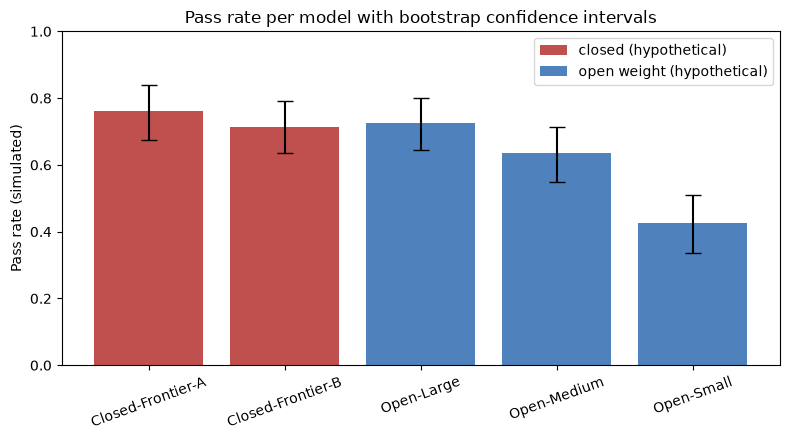

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#c0504d" if k == "closed" else "#4f81bd" for k in models["kind"]]
yerr = np.vstack([models["pass_rate"] - models["ci_low"], models["ci_high"] - models["pass_rate"]])
ax.bar(models["model"], models["pass_rate"], color=colors, yerr=yerr, capsize=6)
ax.set_ylabel("Pass rate (simulated)")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
ax.bar(0, 0, color="#c0504d", label="closed (hypothetical)")
ax.bar(0, 0, color="#4f81bd", label="open weight (hypothetical)")
ax.legend(loc="upper right")
plt.title("Pass rate per model with bootstrap confidence intervals")
plt.tight_layout()
plt.show()

Look at how much the bars overlap. With 40 tasks, two models a few points apart are often statistically indistinguishable. That's the "30 of 40 versus 34 of 40" situation from the post: the gap might be real, or it might be the task sample.

## Step 5: Who sits on the cost and quality frontier?
A model is on the frontier if no other model is both cheaper *and* better. I sort the models by cost and keep each one that beats every cheaper model's pass rate. Anything off the frontier is dominated: you could pay less and get at least as much. I also print the cost per *passed* task, which is the number finance will actually ask about.

In [6]:
by_cost = models.sort_values("cost_per_task_usd")
best_so_far = -1.0
frontier = []
for _, row in by_cost.iterrows():
    on = row["pass_rate"] > best_so_far
    frontier.append(on)
    if on:
        best_so_far = row["pass_rate"]
models["on_frontier"] = pd.Series(frontier, index=by_cost.index)
models["cost_per_pass_usd"] = models["cost_per_task_usd"] / models["pass_rate"]

print(models[["model", "cost_per_task_usd", "pass_rate", "cost_per_pass_usd", "on_frontier"]]
      .round(3).to_string(index=False))

            model  cost_per_task_usd  pass_rate  cost_per_pass_usd  on_frontier
Closed-Frontier-A               0.90      0.760              1.184         True
Closed-Frontier-B               0.55      0.715              0.769        False
       Open-Large               0.12      0.725              0.166         True
      Open-Medium               0.05      0.635              0.079         True
       Open-Small               0.02      0.425              0.047         True


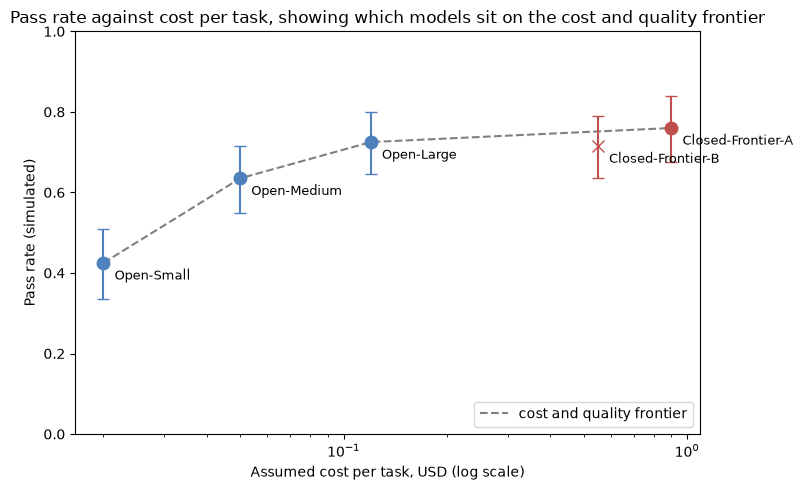

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
front = models[models["on_frontier"]].sort_values("cost_per_task_usd")
ax.plot(front["cost_per_task_usd"], front["pass_rate"], "--", color="grey", label="cost and quality frontier")
for _, row in models.iterrows():
    color = "#c0504d" if row["kind"] == "closed" else "#4f81bd"
    marker = "o" if row["on_frontier"] else "x"
    ax.errorbar(row["cost_per_task_usd"], row["pass_rate"],
                yerr=[[row["pass_rate"] - row["ci_low"]], [row["ci_high"] - row["pass_rate"]]],
                fmt=marker, color=color, markersize=9, capsize=4)
    ax.annotate(row["model"], (row["cost_per_task_usd"], row["pass_rate"]),
                textcoords="offset points", xytext=(8, -12), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Assumed cost per task, USD (log scale)")
ax.set_ylabel("Pass rate (simulated)")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.title("Pass rate against cost per task, showing which models sit on the cost and quality frontier")
plt.tight_layout()
plt.show()

Circles are on the frontier, crosses are dominated. In this made up example, one open weight model lands close to the top closed model for a fraction of the cost, while the other open models trail. That mirrors the *shape* of the claim in the abstract ("an open weight model", singular). It does not reproduce any real numbers.

## Step 6: How much does a single run move?
Finally, I compute each model's pass rate for each of the five runs separately. If you only ran your test once, you'd see one of these dots and think it was the answer. The spread is why I tell people to run every task more than once.

In [8]:
per_run = results.mean(axis=1)  # shape: (models, runs)
spread = pd.DataFrame({
    "model": models["model"],
    "min_run": per_run.min(axis=1),
    "max_run": per_run.max(axis=1),
    "range_pts": (per_run.max(axis=1) - per_run.min(axis=1)) * 100,
})
print(spread.round(3).to_string(index=False))

# Share of tasks where a model's runs disagreed (some passed, some failed)
flaky = ((task_means > 0) & (task_means < 1)).mean(axis=1)
for name, f in zip(models["model"], flaky):
    print(f"{name}: {f:.0%} of tasks gave mixed pass/fail across runs")

            model  min_run  max_run  range_pts
Closed-Frontier-A    0.675    0.850       17.5
Closed-Frontier-B    0.650    0.875       22.5
       Open-Large    0.650    0.800       15.0
      Open-Medium    0.500    0.725       22.5
       Open-Small    0.375    0.475       10.0
Closed-Frontier-A: 57% of tasks gave mixed pass/fail across runs
Closed-Frontier-B: 72% of tasks gave mixed pass/fail across runs
Open-Large: 72% of tasks gave mixed pass/fail across runs
Open-Medium: 82% of tasks gave mixed pass/fail across runs
Open-Small: 82% of tasks gave mixed pass/fail across runs


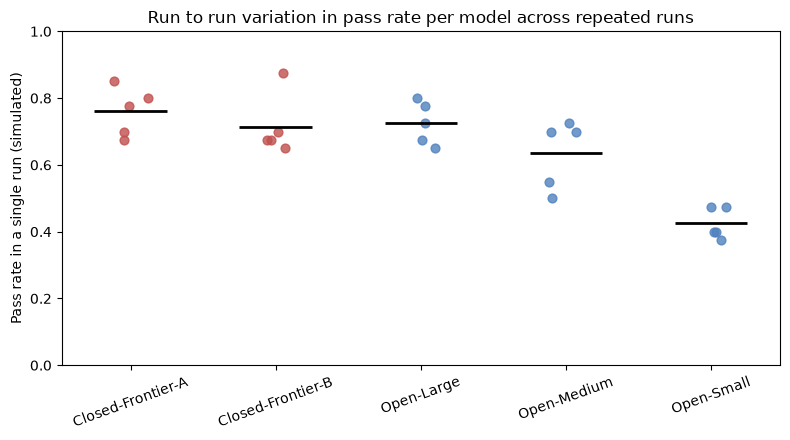

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(models))
for i in range(len(models)):
    color = "#c0504d" if models.loc[i, "kind"] == "closed" else "#4f81bd"
    jitter = rng.uniform(-0.12, 0.12, size=N_RUNS)
    ax.scatter(x[i] + jitter, per_run[i], color=color, alpha=0.8, s=40)
    ax.hlines(per_run[i].mean(), x[i] - 0.25, x[i] + 0.25, color="black", linewidth=2)
ax.set_xticks(x)
ax.set_xticklabels(models["model"], rotation=20)
ax.set_ylabel("Pass rate in a single run (simulated)")
ax.set_ylim(0, 1)
plt.title("Run to run variation in pass rate per model across repeated runs")
plt.tight_layout()
plt.show()

## What to take away
Three things carry over to a real test on your own threat reports: put intervals on your pass rates, compare quality and cost together, and run each task more than once. The numbers here are simulated and the setup is deliberately simple (no LLM judges, no false positive counts, no per attack type breakdown). Swap in your own pass/fail grid and the same code will tell you where your shortlisted models actually sit.